# Import library

In [84]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score,calinski_harabasz_score

# Data collection

In [85]:
college_data = pd.read_csv("college_list.csv")
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


# Data understanding

In [86]:
college_data.isnull().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [87]:
college_data.shape

(500, 6)

In [88]:
college_data.duplicated().sum()

np.int64(0)

In [89]:
college_data.dtypes

College_Name              object
Student_Faculty_Ratio      int64
Annual_Fees_INR            int64
Placement_Percentage       int64
Average_Package_LPA      float64
Infrastructure_Score       int64
dtype: object

In [47]:
college_data.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


In [90]:
college_data["Student_Faculty_Ratio"].unique()

array([14, 27, 22, 18, 15, 28, 26, 11, 10, 29,  9, 19, 13,  8, 24, 17, 23,
       12, 16, 25, 21, 20])

# Data preparation

In [91]:
X = college_data.drop(labels = "College_Name",axis=1)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


In [92]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled= pd.DataFrame(X_scaled )
X_scaled

,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [93]:
X_scaled.mean().round(4),X_scaled.std().round(4)

(0    0.0
 1    0.0
 2   -0.0
 3    0.0
 4   -0.0
 dtype: float64,
 0    1.001
 1    1.001
 2    1.001
 3    1.001
 4    1.001
 dtype: float64)

# model building

In [94]:
kmean_cluster = KMeans(n_clusters=3,random_state=123)
clusters_new = kmean_cluster.fit_predict(X_scaled)
clusters_new


array([1, 2, 2, 1, 1, 0, 2, 0, 1, 2, 0, 2, 2, 1, 0, 0, 1, 2, 0, 2, 0, 1,
       1, 0, 0, 0, 1, 0, 2, 0, 2, 0, 2, 1, 1, 0, 2, 0, 1, 2, 0, 1, 0, 0,
       1, 2, 2, 2, 0, 2, 2, 2, 0, 1, 0, 0, 1, 2, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 2, 0, 0, 2, 2, 1, 2, 0, 1, 1, 0, 0, 0, 2, 1, 0, 0, 1,
       1, 1, 1, 0, 2, 1, 2, 0, 0, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1,
       2, 2, 2, 2, 2, 0, 2, 1, 1, 2, 1, 0, 1, 1, 1, 2, 1, 1, 0, 2, 1, 2,
       2, 2, 2, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 2, 0, 1, 1, 0, 2, 2, 2, 2,
       0, 0, 0, 1, 2, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 2, 0, 0, 0, 2, 2,
       2, 2, 0, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 1, 2, 1, 1, 2, 0, 1, 0, 1,
       1, 1, 0, 0, 2, 1, 0, 2, 2, 0, 2, 0, 2, 1, 1, 1, 0, 1, 0, 2, 0, 2,
       0, 2, 2, 0, 2, 1, 1, 2, 0, 2, 2, 2, 0, 2, 2, 1, 2, 0, 0, 2, 1, 1,
       2, 1, 1, 1, 0, 1, 1, 2, 2, 0, 1, 0, 2, 1, 0, 2, 2, 0, 1, 1, 2, 2,
       2, 0, 1, 2, 0, 0, 1, 2, 1, 0, 1, 2, 1, 1, 1, 0, 0, 0, 0, 0, 1, 2,
       2, 1, 0, 2, 0, 0, 0, 0, 1, 2, 2, 2, 2, 2, 1,

### two way you get the predict formet one is labels_ and fit_predict

In [23]:
kmean_cluster.labels_

array([1, 2, 2, 1, 1, 0, 2, 0, 1, 2, 0, 2, 2, 1, 0, 0, 1, 2, 0, 2, 0, 1,
       1, 0, 0, 0, 1, 0, 2, 0, 2, 0, 2, 1, 1, 0, 2, 0, 1, 2, 0, 1, 0, 0,
       1, 2, 2, 2, 0, 2, 2, 2, 0, 1, 0, 0, 1, 2, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 2, 0, 0, 2, 2, 1, 2, 0, 1, 1, 0, 0, 0, 2, 1, 0, 0, 1,
       1, 1, 1, 0, 2, 1, 2, 0, 0, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1,
       2, 2, 2, 2, 2, 0, 2, 1, 1, 2, 1, 0, 1, 1, 1, 2, 1, 1, 0, 2, 1, 2,
       2, 2, 2, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 2, 0, 1, 1, 0, 2, 2, 2, 2,
       0, 0, 0, 1, 2, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 2, 0, 0, 0, 2, 2,
       2, 2, 0, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 1, 2, 1, 1, 2, 0, 1, 0, 1,
       1, 1, 0, 0, 2, 1, 0, 2, 2, 0, 2, 0, 2, 1, 1, 1, 0, 1, 0, 2, 0, 2,
       0, 2, 2, 0, 2, 1, 1, 2, 0, 2, 2, 2, 0, 2, 2, 1, 2, 0, 0, 2, 1, 1,
       2, 1, 1, 1, 0, 1, 1, 2, 2, 0, 1, 0, 2, 1, 0, 2, 2, 0, 1, 1, 2, 2,
       2, 0, 1, 2, 0, 0, 1, 2, 1, 0, 1, 2, 1, 1, 1, 0, 0, 0, 0, 0, 1, 2,
       2, 1, 0, 2, 0, 0, 0, 0, 1, 2, 2, 2, 2, 2, 1,

### Clustering is DONE here. Let's put this back to the original Dataset for further Data Mining Operations

## LEVEL 2: Attach Clusters to Dataset

In [95]:
college_data["college_level"] = clusters_new
college_data.head(10)

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,college_level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,1
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,2
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,2
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,1
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,1
5,Government College of Technology Coimbatore - ...,28,226582,45,9.32,4,0
6,SSN College of Engineering - Campus 1,14,195983,93,4.51,3,2
7,SRM Institute of Science and Technology - Camp...,26,220103,88,8.33,9,0
8,VIT Vellore - Campus 1,18,249798,69,6.94,9,1
9,SASTRA University - Campus 1,18,168429,95,7.73,4,2


# Finding Cluster Centroids

In [26]:
kmean_cluster.cluster_centers_

array([[ 0.87139616,  0.00217856, -0.16324398,  0.73919839, -0.34371867],
       [-0.83803713,  0.30609537, -0.41113704,  0.2685074 ,  0.34297126],
       [ 0.09376921, -0.32436861,  0.58082084, -0.95202172, -0.05005874]])

In [96]:
X.head(10)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
5,28,226582,45,9.32,4
6,14,195983,93,4.51,3
7,26,220103,88,8.33,9
8,18,249798,69,6.94,9
9,18,168429,95,7.73,4


In [97]:
X["college_level"] = clusters_new
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,college_level
0,14,113042,59,9.20,8,1
1,27,115999,67,3.07,7,2
2,22,47955,50,3.40,9,2
3,18,67841,43,4.64,8,1
4,15,100640,54,4.66,9,1
...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0
496,12,39111,76,3.62,7,2
497,16,199182,64,3.88,3,2
498,10,46389,77,9.31,6,1


### Note: This is the Most Important Data Mining Step post Clustering, but before we give labels

In [98]:
X.groupby(by="college_level").agg(['mean'])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
college_level,,,,,
0,23.901961,138902.843137,66.196078,9.146536,5.287582
1,12.488764,158312.404494,61.938202,7.774438,6.662921
2,18.710059,118048.000000,78.976331,4.216509,5.875740


In [99]:
X.groupby(by="college_level").agg(['min','max'])

Student_Faculty_Ratio     Annual_Fees_INR          ... Average_Package_LPA        Infrastructure_Score    
                                min max             min     max  ...                 min    max                  min max
college_level                                                    ...                                                    
0                                11  29           31062  249536  ...                4.45  11.99                    3   9
1                                 8  25           31062  249930  ...                2.01  11.91                    3   9
2                                 8  29           30404  247776  ...                2.00   9.71                    3   9

[3 rows x 10 columns]

In [103]:
cluster_names = {0: "Best Colleges",
                 1: "Mid-Level Colleges",
                 2: "Emerging / Lower-Level Colleges"}

X["Category"] = X["college_level"].map(cluster_names)

In [104]:
X.head(10)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,college_level,Category
0,14,113042,59,9.20,8,1,Mid-Level Colleges
1,27,115999,67,3.07,7,2,Emerging / Lower-Level Colleges
2,22,47955,50,3.40,9,2,Emerging / Lower-Level Colleges
3,18,67841,43,4.64,8,1,Mid-Level Colleges
4,15,100640,54,4.66,9,1,Mid-Level Colleges
5,28,226582,45,9.32,4,0,Best Colleges
6,14,195983,93,4.51,3,2,Emerging / Lower-Level Colleges
7,26,220103,88,8.33,9,0,Best Colleges
8,18,249798,69,6.94,9,1,Mid-Level Colleges
9,18,168429,95,7.73,4,2,Emerging / Lower-Level Colleges


### LEVEL 3: Now it's time to Transition to Supervised Learning






The End!!

### model building

In [105]:
X.head(10)

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,college_level,Category
0,14,113042,59,9.20,8,1,Mid-Level Colleges
1,27,115999,67,3.07,7,2,Emerging / Lower-Level Colleges
2,22,47955,50,3.40,9,2,Emerging / Lower-Level Colleges
3,18,67841,43,4.64,8,1,Mid-Level Colleges
4,15,100640,54,4.66,9,1,Mid-Level Colleges
5,28,226582,45,9.32,4,0,Best Colleges
6,14,195983,93,4.51,3,2,Emerging / Lower-Level Colleges
7,26,220103,88,8.33,9,0,Best Colleges
8,18,249798,69,6.94,9,1,Mid-Level Colleges
9,18,168429,95,7.73,4,2,Emerging / Lower-Level Colleges


In [106]:
input_data = X.drop(labels=["college_level","Category"],axis=1)
input_data

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


In [107]:
y=X["college_level"]
y

0      1
1      2
2      2
3      1
4      1
      ..
495    0
496    2
497    2
498    1
499    2
Name: college_level, Length: 500, dtype: int32

### 

In [108]:
X_train, X_test, y_train, y_test = train_test_split(input_data,y,test_size=0.20,random_state=123,shuffle=True,stratify=y)

In [109]:
X_train.shape,y_train.shape

((400, 5), (400,))

In [ ]:
#train

In [110]:
kmean_cluster = KMeans(n_clusters=3,random_state=123)
kmean_cluster.fit(X_train,y_train)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,123
,copy_x,True
,algorithm,'lloyd'


In [111]:
y_predict_train_cluster = kmean_cluster.predict(X_train)
y_predict_train_cluster

array([1, 1, 2, 0, 1, 0, 2, 2, 0, 1, 1, 2, 0, 0, 0, 2, 2, 0, 2, 1, 0, 1,
       2, 0, 1, 0, 0, 2, 1, 0, 1, 1, 0, 0, 2, 1, 0, 2, 2, 2, 2, 2, 0, 0,
       0, 0, 2, 0, 2, 0, 2, 1, 1, 2, 2, 1, 2, 0, 2, 2, 1, 2, 1, 1, 2, 0,
       1, 2, 1, 1, 2, 1, 0, 0, 0, 0, 2, 2, 2, 1, 0, 2, 2, 0, 1, 2, 2, 1,
       2, 2, 0, 2, 0, 0, 1, 1, 2, 0, 1, 2, 1, 0, 1, 1, 2, 2, 1, 0, 1, 0,
       2, 0, 1, 0, 1, 1, 2, 0, 2, 2, 1, 0, 1, 2, 1, 1, 2, 2, 0, 0, 0, 0,
       1, 2, 0, 2, 1, 0, 0, 2, 2, 2, 1, 0, 1, 2, 1, 0, 0, 2, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 2, 2, 0, 2, 0, 0, 2, 2, 2, 2, 2, 0, 0, 0,
       0, 2, 0, 1, 2, 2, 1, 0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 2, 0, 0, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 2, 2, 0, 0, 1, 0, 2, 0, 0, 0, 2, 0, 2, 1,
       2, 1, 2, 2, 1, 1, 0, 2, 0, 2, 1, 1, 0, 0, 2, 2, 1, 2, 0, 0, 2, 2,
       2, 1, 2, 0, 1, 2, 1, 0, 1, 0, 0, 2, 2, 2, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 2, 2, 1, 0, 1, 1, 0, 0, 1, 0, 0, 2, 0, 1, 2, 0, 2, 0, 1, 0,
       2, 2, 2, 0, 1, 1, 1, 2, 2, 1, 0, 0, 1, 0, 0,

In [114]:
print("silhouette_score:",silhouette_score(X_train,y_predict_train_cluster))
print("calinski_score:",calinski_harabasz_score(X_train,y_predict_train_cluster))

silhouette_score: 0.5832321634050964
calinski_score: 1523.8367008960063


### test

In [116]:
y_predict_test_cluster = kmean_cluster.predict(X_test)
y_predict_test_cluster

array([0, 1, 2, 0, 2, 1, 0, 0, 1, 2, 0, 0, 2, 1, 2, 1, 1, 0, 2, 2, 2, 0,
       1, 2, 1, 0, 1, 0, 0, 2, 2, 1, 0, 2, 1, 1, 0, 1, 2, 1, 2, 1, 2, 0,
       1, 0, 1, 2, 0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 2, 2, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 2, 1, 1, 1, 1, 2, 0, 2, 2, 2,
       0, 2, 2, 1, 0, 1, 1, 1, 1, 2, 1, 1], dtype=int32)

In [118]:
print("silhouette_score:",silhouette_score(X_test,y_predict_test_cluster))
print("calinski_score:",calinski_harabasz_score(X_test,y_predict_test_cluster))

silhouette_score: 0.59209079336869
calinski_score: 425.11207651952583


In [121]:
wcss = []
for i in range(2,11):
    X_train, X_test, y_train, y_test = train_test_split(input_data,y,test_size=0.20,random_state=123,shuffle=True,stratify=y)
    kmean_cluster = KMeans(n_clusters=i,random_state=123)
    kmean_cluster.fit(X_train,y_train)
    wcss.append(kmean_cluster.inertia_)
    y_predict_train_cluster = kmean_cluster.predict(X_train)
    y_predict_train_cluster
    y_predict_test_cluster = kmean_cluster.predict(X_test)
    y_predict_test_cluster
    print("silhouette_score:",silhouette_score(X_train,y_predict_train_cluster))
    print("calinski_score:",calinski_harabasz_score(X_train,y_predict_train_cluster))
    print("silhouette_score:",silhouette_score(X_test,y_predict_test_cluster))
    print("calinski_score:",calinski_harabasz_score(X_test,y_predict_test_cluster))
    

silhouette_score: 0.6161336827834473
calinski_score: 1138.7763371972371
silhouette_score: 0.6606509176693584
calinski_score: 353.78754137502585
silhouette_score: 0.5832321634050964
calinski_score: 1523.8367008960063
silhouette_score: 0.59209079336869
calinski_score: 425.11207651952583
silhouette_score: 0.5599888072560989
calinski_score: 1875.003002754662
silhouette_score: 0.5389634139426887
calinski_score: 475.814175804028
silhouette_score: 0.5727717156368776
calinski_score: 2411.234810922747
silhouette_score: 0.5485636393571941
calinski_score: 612.878661501606
silhouette_score: 0.5568270163503781
calinski_score: 2736.657690893315
silhouette_score: 0.5473754849289505
calinski_score: 707.1602182608336
silhouette_score: 0.5401894441237647
calinski_score: 2937.5097533523767
silhouette_score: 0.49461080839054283
calinski_score: 690.5551643832193
silhouette_score: 0.5296425362873227
calinski_score: 3238.7169252214044
silhouette_score: 0.5572647906966377
calinski_score: 920.5150635701591
sil

### doubt-----

In [75]:
from sklearn.ensemble import RandomForestClassifier

In [76]:
rf_model = RandomForestClassifier()
rf_model.fit(X_train,y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [77]:
y_predict_train_rf = rf_model.predict(X_train)
y_predict_train_rf

array([1, 1, 0, 0, 1, 1, 2, 2, 0, 1, 1, 0, 0, 1, 2, 2, 1, 1, 2, 1, 2, 1,
       2, 1, 1, 1, 2, 1, 1, 2, 0, 1, 2, 1, 2, 1, 2, 1, 2, 2, 0, 0, 2, 1,
       2, 0, 2, 0, 2, 1, 2, 0, 2, 0, 1, 0, 0, 2, 2, 2, 1, 0, 1, 0, 2, 0,
       1, 2, 1, 0, 2, 0, 1, 1, 1, 1, 1, 2, 0, 2, 0, 2, 2, 2, 0, 2, 0, 2,
       0, 1, 0, 0, 1, 1, 0, 1, 2, 1, 2, 2, 0, 2, 0, 1, 2, 1, 1, 1, 1, 2,
       0, 2, 0, 2, 2, 1, 1, 0, 0, 2, 1, 2, 0, 0, 1, 0, 2, 0, 0, 0, 1, 2,
       1, 0, 0, 1, 0, 0, 2, 2, 1, 2, 0, 1, 2, 0, 2, 2, 0, 1, 1, 2, 0, 0,
       2, 2, 0, 1, 2, 2, 0, 2, 2, 2, 0, 0, 0, 0, 2, 0, 2, 1, 2, 2, 2, 0,
       1, 0, 2, 1, 0, 2, 1, 1, 0, 2, 0, 0, 2, 1, 0, 0, 1, 0, 2, 1, 0, 0,
       2, 0, 0, 1, 0, 2, 0, 0, 2, 0, 1, 2, 2, 0, 1, 2, 2, 0, 2, 1, 2, 2,
       1, 1, 2, 2, 1, 0, 0, 0, 1, 0, 0, 2, 0, 1, 1, 0, 2, 2, 1, 0, 2, 0,
       2, 2, 2, 2, 0, 2, 1, 0, 2, 1, 2, 0, 2, 0, 1, 2, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 0, 1, 0, 2,
       0, 0, 1, 2, 1, 2, 0, 2, 0, 1, 1, 0, 0, 1, 2,

In [83]:

print("silhouette_score:",silhouette_score(y_train,y_predict_train_cluster))
print("calinski_score:",calinski_harabasz_score(y_train,y_predict_train_cluster))

ValueError: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

### But, how to decide the Optimal Number of Clusters?

In [52]:
kmean_cluster = KMeans(n_clusters=3,random_state=123)
clusters_new = kmean_cluster.fit_predict(X_scaled)
clusters_new

array([1, 2, 2, 1, 1, 0, 2, 0, 1, 2, 0, 2, 2, 1, 0, 0, 1, 2, 0, 2, 0, 1,
       1, 0, 0, 0, 1, 0, 2, 0, 2, 0, 2, 1, 1, 0, 2, 0, 1, 2, 0, 1, 0, 0,
       1, 2, 2, 2, 0, 2, 2, 2, 0, 1, 0, 0, 1, 2, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 2, 0, 0, 2, 2, 1, 2, 0, 1, 1, 0, 0, 0, 2, 1, 0, 0, 1,
       1, 1, 1, 0, 2, 1, 2, 0, 0, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1,
       2, 2, 2, 2, 2, 0, 2, 1, 1, 2, 1, 0, 1, 1, 1, 2, 1, 1, 0, 2, 1, 2,
       2, 2, 2, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 2, 0, 1, 1, 0, 2, 2, 2, 2,
       0, 0, 0, 1, 2, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 2, 0, 0, 0, 2, 2,
       2, 2, 0, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 1, 2, 1, 1, 2, 0, 1, 0, 1,
       1, 1, 0, 0, 2, 1, 0, 2, 2, 0, 2, 0, 2, 1, 1, 1, 0, 1, 0, 2, 0, 2,
       0, 2, 2, 0, 2, 1, 1, 2, 0, 2, 2, 2, 0, 2, 2, 1, 2, 0, 0, 2, 1, 1,
       2, 1, 1, 1, 0, 1, 1, 2, 2, 0, 1, 0, 2, 1, 0, 2, 2, 0, 1, 1, 2, 2,
       2, 0, 1, 2, 0, 0, 1, 2, 1, 0, 1, 2, 1, 1, 1, 0, 0, 0, 0, 0, 1, 2,
       2, 1, 0, 2, 0, 0, 0, 0, 1, 2, 2, 2, 2, 2, 1,

In [53]:
kmean_cluster.inertia_

1842.6441404313482

### The K-means algorithm aims to choose centroids that minimise the inertia, or within-cluster sum-of-squares criterion:

In [57]:
wcss = []
for i in range(1,11):
    kmean_cluster = KMeans(n_clusters=i,random_state=123)
    kmean_cluster.fit_predict(X_scaled)
    wcss.append(kmean_cluster.inertia_)

    

In [58]:
X_scaled


,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [59]:
wcss

[2500.0,
 2116.146420072567,
 1842.6441404313482,
 1645.314562842257,
 1467.114233137894,
 1379.135984525568,
 1289.822329066612,
 1229.9769681245727,
 1160.1076312943665,
 1090.5733088472773]

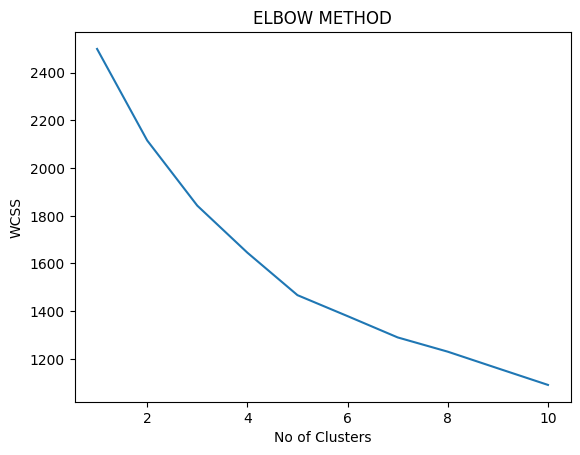

In [60]:

plt.plot(range(1,11),wcss)
plt.title('ELBOW METHOD')
plt.xlabel('No of Clusters')
plt.ylabel('WCSS')
plt.show()

### Task:
Silhoutee Score
calinski harabasz score
IRIS Dataset - apply this clustering techniques and check